# Détection de tumeurs cérébrales sur IRM par transfert d'apprentissage (VGG16)

**Auteur :** Baye Gorgoumack Niang
**Projet :** SANTE IA SENIA
**Date :** octobre 2026

---

## Objectif

L'idée est de construire un classifieur binaire capable de dire, à partir d'une coupe IRM du cerveau, si une tumeur est présente (**oui**) ou non (**non**).

Le jeu de données est petit (253 images). Entraîner un CNN à partir de zéro mènerait droit au sur-apprentissage, donc je m'appuie sur **VGG16 pré-entraîné sur ImageNet**, en deux temps :

1. **Extraction de caractéristiques** : la base convolutive est gelée et seule une petite tête de classification est entraînée.
2. **Fine-tuning** : le dernier bloc convolutif de VGG16 est dégelé et réentraîné avec un taux d'apprentissage très faible.

## Démarche

| Étape | Contenu |
|---|---|
| 1 | Configuration de l'environnement |
| 2 | Récupération et inventaire des données |
| 3 | Découpage stratifié train / validation / test |
| 4 | Exploration visuelle |
| 5 | Prétraitement : recadrage automatique du cerveau |
| 6 | Pipeline `tf.data` et augmentation |
| 7 | Modèle et entraînement (2 phases) |
| 8 | Évaluation sur le jeu de test |
| 9 | Inférence sur une nouvelle image |

> ⚠️ Ce travail est un exercice de recherche. Il ne remplace en aucun cas l'avis d'un radiologue.

## 1. Configuration de l'environnement

In [1]:
# Remarque Windows : TensorFlow doit être importé AVANT scikit-learn.
# scikit-learn embarque sa propre msvcp140.dll (plus ancienne) qui, chargée en premier,
# fait échouer l'initialisation du runtime TensorFlow ("DLL load failed").
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

import os
import random
from pathlib import Path

import cv2
import imutils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

print("TensorFlow :", tf.__version__)
print("GPU disponibles :", tf.config.list_physical_devices('GPU') or "aucun (entraînement sur CPU)")

TensorFlow : 2.20.0
GPU disponibles : aucun (entraînement sur CPU)


In [2]:
# Tous les paramètres du projet au même endroit
CONFIG = {
    "graine": 42,
    "taille_img": (224, 224),     # taille d'entrée attendue par VGG16
    "batch": 16,
    "part_test": 0.15,
    "part_val": 0.15,
    "epochs_phase1": 30,
    "epochs_phase2": 15,
    "lr_phase1": 1e-3,            # 1e-4 testé : trop lent, la tête n'apprend presque rien en 30 époques
    "lr_phase2": 1e-5,
    "seuil": 0.5,
}

def fixer_graines(graine):
    """Rend les résultats reproductibles (dans la mesure du possible sur CPU)."""
    random.seed(graine)
    np.random.seed(graine)
    tf.random.set_seed(graine)

fixer_graines(CONFIG["graine"])
sns.set_theme(style="whitegrid")
CLASSES = ["non", "oui"]   # 0 = pas de tumeur, 1 = tumeur

## 2. Récupération et inventaire des données

Source : dataset Kaggle public *Brain MRI Images for Brain Tumor Detection* (navoneel). Il est téléchargé avec `kagglehub` et mis en cache localement, donc le notebook reste exécutable sur n'importe quelle machine.

Plutôt que de copier les fichiers dans des sous-dossiers, je construis un **inventaire** (un DataFrame chemin → étiquette). C'est plus simple à manipuler et ça ne duplique rien sur le disque.

In [3]:
racine = Path(kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection"))
dossier_images = racine / "brain_tumor_dataset"

extensions = {".jpg", ".jpeg", ".png"}
inventaire = pd.DataFrame(
    [{"chemin": str(f), "classe": classe, "label": CLASSES.index(classe)}
     for classe in CLASSES
     for f in sorted((dossier_images / ("no" if classe == "non" else "yes")).iterdir())
     if f.suffix.lower() in extensions]
)

print(f"{len(inventaire)} images trouvées")
inventaire["classe"].value_counts()

253 images trouvées


classe
oui    155
non     98
Name: count, dtype: int64

In [4]:
# Contrôle qualité : chaque fichier doit être lisible, et on relève sa taille d'origine
def lire_dimensions(chemin):
    img = cv2.imread(chemin)
    return (None, None) if img is None else img.shape[:2]

inventaire[["hauteur", "largeur"]] = inventaire["chemin"].apply(lambda c: pd.Series(lire_dimensions(c)))
illisibles = inventaire["hauteur"].isna().sum()
print("Images illisibles :", illisibles)
inventaire = inventaire.dropna().reset_index(drop=True)
inventaire[["hauteur", "largeur"]].describe().round(0)

Images illisibles : 0


,hauteur,largeur
count,253.0,253.0
mean,386.0,354.0
std,213.0,217.0
min,168.0,150.0
25%,248.0,225.0
50%,331.0,278.0
75%,442.0,400.0
max,1427.0,1920.0


## 3. Découpage stratifié train / validation / test

Le découpage est **stratifié** pour conserver la même proportion oui/non dans chaque sous-ensemble, ce qui compte vu le déséquilibre (~61 % de « oui »). Le jeu de test est mis de côté dès maintenant et ne sert qu'à l'évaluation finale.

In [5]:
train_val, test = train_test_split(inventaire, test_size=CONFIG["part_test"],
                                   stratify=inventaire["label"], random_state=CONFIG["graine"])
part_val_relative = CONFIG["part_val"] / (1 - CONFIG["part_test"])
train, val = train_test_split(train_val, test_size=part_val_relative,
                              stratify=train_val["label"], random_state=CONFIG["graine"])

repartition = pd.concat({"train": train["classe"].value_counts(),
                         "validation": val["classe"].value_counts(),
                         "test": test["classe"].value_counts()}, axis=1).T
repartition["total"] = repartition.sum(axis=1)
repartition

classe,oui,non,total
train,109,68,177
validation,23,15,38
test,23,15,38


## 4. Exploration visuelle

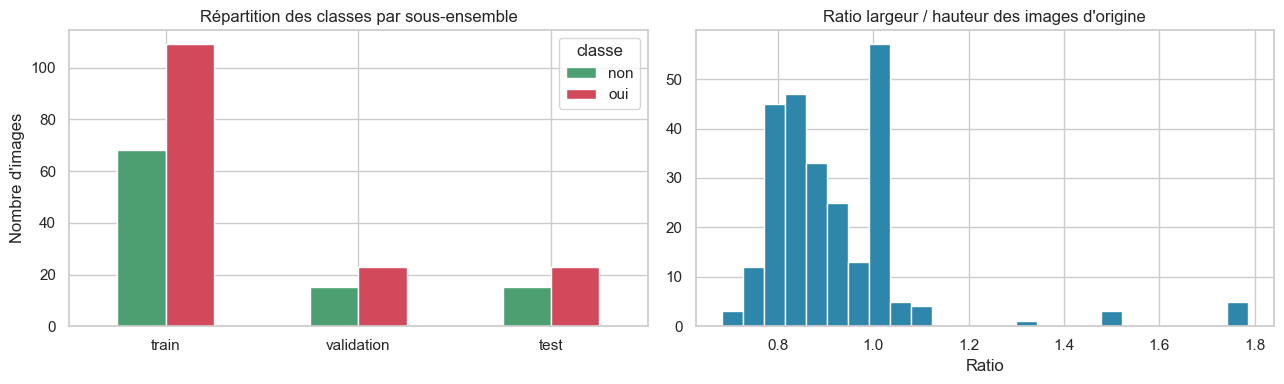

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

repartition[CLASSES].plot(kind="bar", ax=axes[0], color=["#4C9F70", "#D1495B"], rot=0)
axes[0].set_title("Répartition des classes par sous-ensemble")
axes[0].set_ylabel("Nombre d'images")

ratios = inventaire["largeur"] / inventaire["hauteur"]
axes[1].hist(ratios, bins=25, color="#2E86AB")
axes[1].set_title("Ratio largeur / hauteur des images d'origine")
axes[1].set_xlabel("Ratio")

plt.tight_layout()
plt.show()

Les images ont des tailles et des cadrages très variables. Beaucoup ont de larges bordures noires autour du crâne, d'où l'étape de recadrage qui suit.

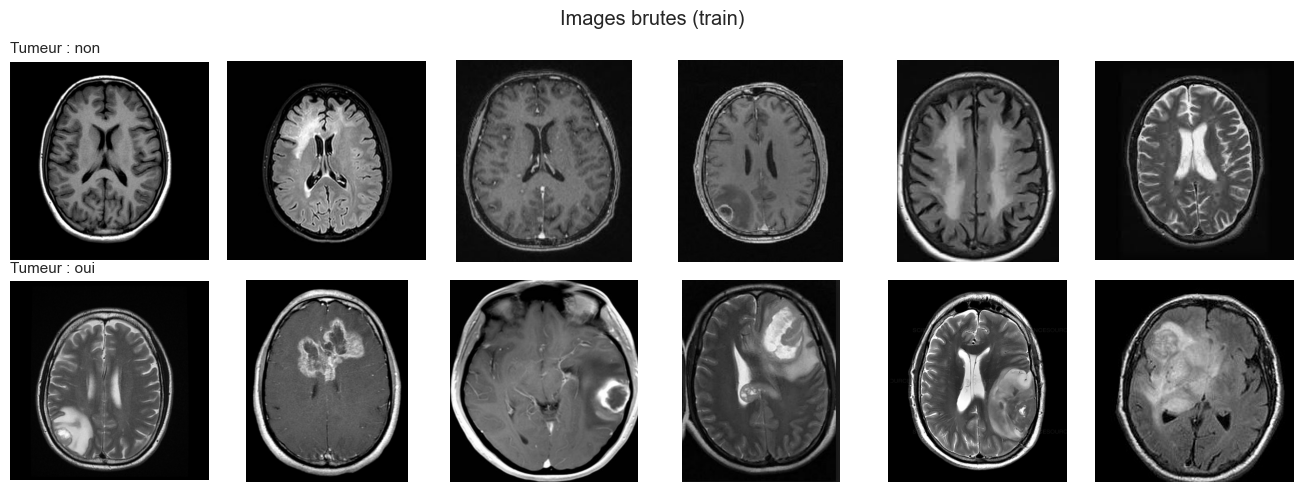

In [7]:
def lire_rgb(chemin):
    """OpenCV lit en BGR : on convertit en RGB pour l'affichage et pour VGG16."""
    return cv2.cvtColor(cv2.imread(chemin), cv2.COLOR_BGR2RGB)

def afficher_grille(df, n_par_classe=6, transformation=None, titre=""):
    fig, axes = plt.subplots(2, n_par_classe, figsize=(2.2 * n_par_classe, 5))
    for ligne, classe in enumerate(CLASSES):
        echantillon = df[df["classe"] == classe].sample(n_par_classe, random_state=CONFIG["graine"])
        for ax, chemin in zip(axes[ligne], echantillon["chemin"]):
            img = lire_rgb(chemin)
            ax.imshow(transformation(img) if transformation else img)
            ax.axis("off")
        axes[ligne][0].set_title(f"Tumeur : {classe}", loc="left", fontsize=11)
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()

afficher_grille(train, titre="Images brutes (train)")

## 5. Prétraitement : recadrage automatique du cerveau

Principe :
1. passage en niveaux de gris et flou gaussien pour lisser le bruit ;
2. seuillage binaire pour séparer le crâne du fond noir ;
3. érosion puis dilatation pour supprimer les petits artefacts ;
4. on garde le **plus grand contour** et on recadre sur ses points extrêmes (gauche, droite, haut, bas).

Résultat : le modèle se concentre sur le tissu cérébral au lieu des bordures.

In [8]:
def points_extremes(img_rgb, seuil=45):
    """Retourne le plus grand contour de l'image et ses 4 points extrêmes."""
    gris = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    masque = cv2.threshold(gris, seuil, 255, cv2.THRESH_BINARY)[1]
    masque = cv2.erode(masque, None, iterations=2)
    masque = cv2.dilate(masque, None, iterations=2)

    contours = imutils.grab_contours(
        cv2.findContours(masque, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE))
    if not contours:
        return None, None
    c = max(contours, key=cv2.contourArea)
    extremes = {
        "gauche": tuple(c[c[:, :, 0].argmin()][0]),
        "droite": tuple(c[c[:, :, 0].argmax()][0]),
        "haut":   tuple(c[c[:, :, 1].argmin()][0]),
        "bas":    tuple(c[c[:, :, 1].argmax()][0]),
    }
    return c, extremes


def recadrer_cerveau(img_rgb, marge=0):
    """Recadre l'image sur la zone du cerveau ; renvoie l'image intacte si aucun contour n'est trouvé."""
    _, ext = points_extremes(img_rgb)
    if ext is None:
        return img_rgb
    h, w = img_rgb.shape[:2]
    y0, y1 = max(ext["haut"][1] - marge, 0), min(ext["bas"][1] + marge, h)
    x0, x1 = max(ext["gauche"][0] - marge, 0), min(ext["droite"][0] + marge, w)
    return img_rgb[y0:y1, x0:x1]

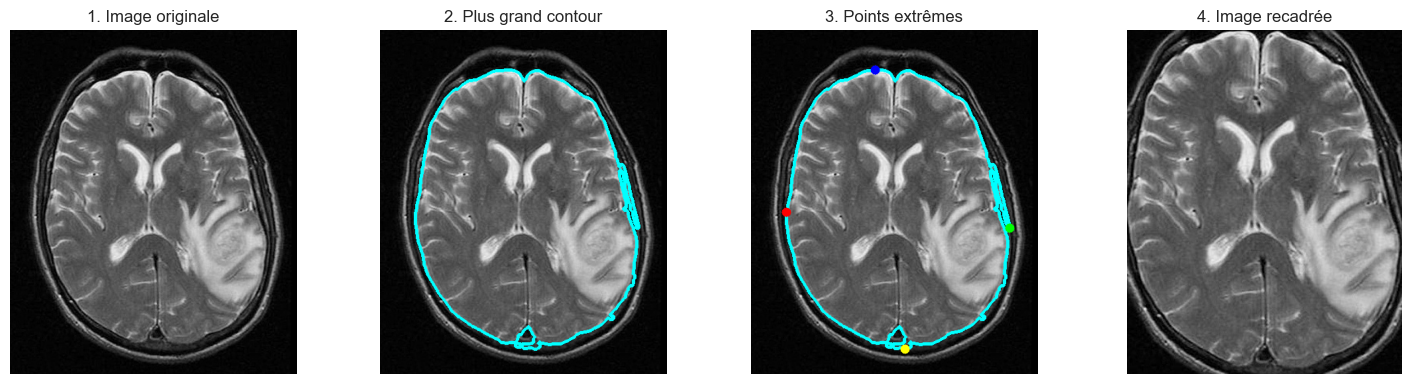

In [9]:
# Illustration des étapes sur une image du jeu d'entraînement
exemple = lire_rgb(train[train["classe"] == "oui"]["chemin"].iloc[0])
contour, ext = points_extremes(exemple)

avec_contour = cv2.drawContours(exemple.copy(), [contour], -1, (0, 255, 255), 3)
couleurs = {"gauche": (255, 0, 0), "droite": (0, 255, 0), "haut": (0, 0, 255), "bas": (255, 255, 0)}
avec_points = avec_contour.copy()
for nom, pt in ext.items():
    cv2.circle(avec_points, pt, 7, couleurs[nom], -1)

etapes = [("1. Image originale", exemple), ("2. Plus grand contour", avec_contour),
          ("3. Points extrêmes", avec_points), ("4. Image recadrée", recadrer_cerveau(exemple))]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (titre, img) in zip(axes, etapes):
    ax.imshow(img); ax.set_title(titre); ax.axis("off")
plt.tight_layout()
plt.show()

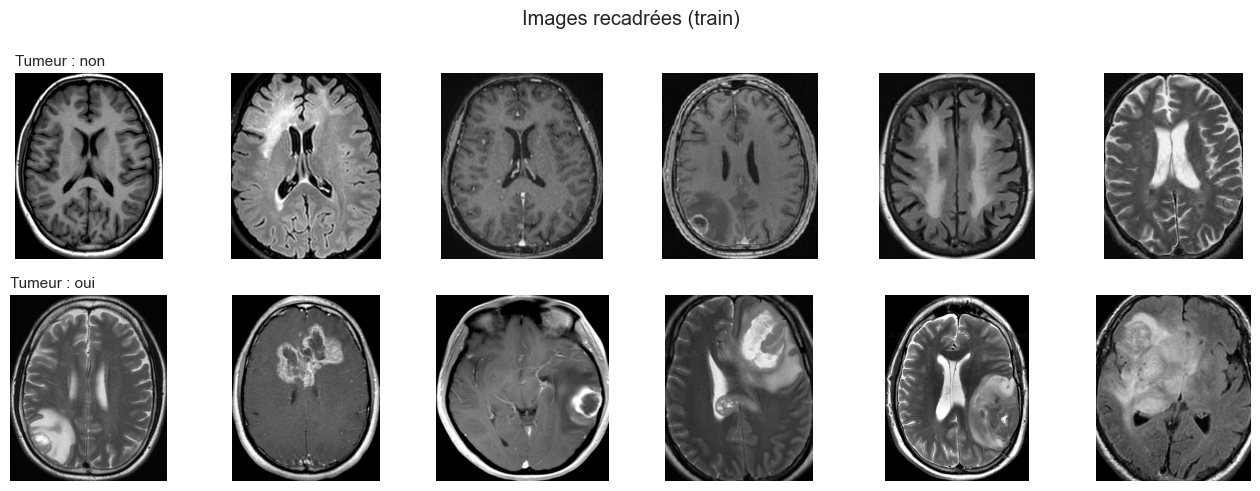

In [10]:
afficher_grille(train, transformation=recadrer_cerveau, titre="Images recadrées (train)")

In [11]:
def charger_ensemble(df):
    """Lit, recadre et redimensionne toutes les images d'un sous-ensemble."""
    X = np.stack([
        cv2.resize(recadrer_cerveau(lire_rgb(c)), CONFIG["taille_img"], interpolation=cv2.INTER_CUBIC)
        for c in df["chemin"]
    ]).astype("float32")
    y = df["label"].to_numpy().astype("float32")
    return X, y

X_train, y_train = charger_ensemble(train)
X_val, y_val = charger_ensemble(val)
X_test, y_test = charger_ensemble(test)

for nom, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{nom:<11} : {X.shape}")

train       : (177, 224, 224, 3)
validation  : (38, 224, 224, 3)
test        : (38, 224, 224, 3)


## 6. Pipeline `tf.data` et augmentation

L'augmentation se fait avec des **couches Keras** intégrées au modèle, au lieu de l'ancien `ImageDataGenerator` désormais obsolète. Avantages : elle tourne dans le graphe TensorFlow, ne s'applique qu'à l'entraînement, et le modèle sauvegardé reste autonome.

Les transformations restent réalistes pour une IRM : petites rotations, retournements, léger zoom, translation et variations de contraste.

In [12]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.2),
], name="augmentation")

AUTOTUNE = tf.data.AUTOTUNE
def creer_dataset(X, y, melanger=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if melanger:
        ds = ds.shuffle(len(X), seed=CONFIG["graine"])
    return ds.batch(CONFIG["batch"]).prefetch(AUTOTUNE)

ds_train = creer_dataset(X_train, y_train, melanger=True)
ds_val = creer_dataset(X_val, y_val)
ds_test = creer_dataset(X_test, y_test)

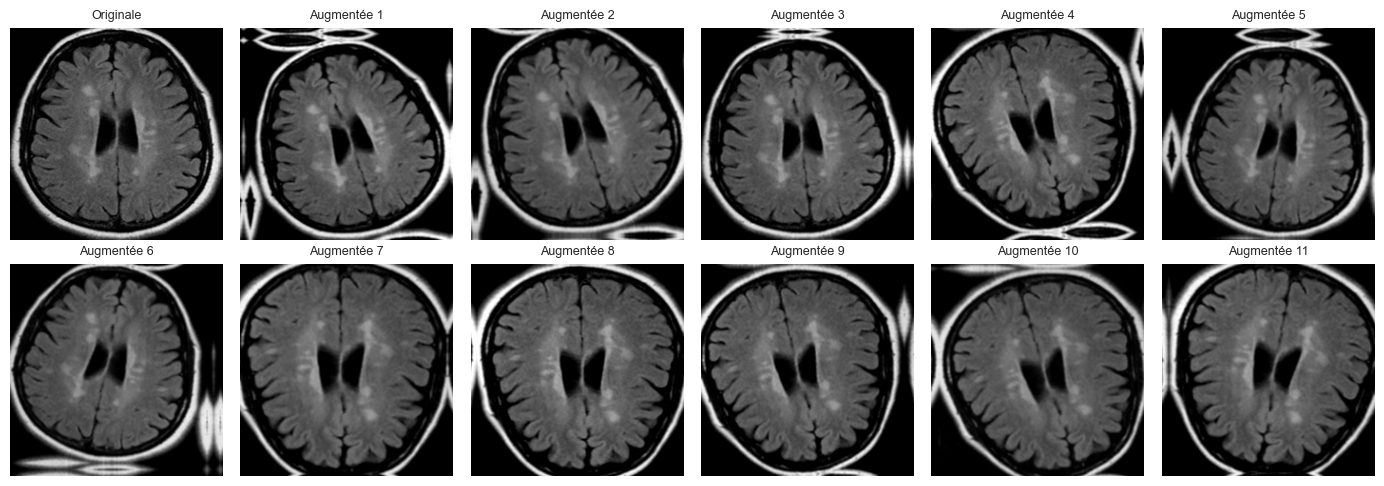

In [13]:
# Aperçu de l'augmentation sur une même image
img = X_train[:1]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    apercu = img[0] if i == 0 else augmentation(img, training=True)[0].numpy()
    ax.imshow(np.clip(apercu, 0, 255).astype("uint8"))
    ax.set_title("Originale" if i == 0 else f"Augmentée {i}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Modèle et entraînement

Architecture :
`Entrée 224×224×3 → augmentation → preprocess_input VGG16 → VGG16 (sans tête) → GlobalAveragePooling → Dropout(0.5) → Dense(1, sigmoïde)`

J'utilise un `GlobalAveragePooling2D` plutôt qu'un `Flatten` : on passe de ~25 000 à 512 caractéristiques, ce qui réduit fortement le nombre de paramètres à apprendre et donc le risque de sur-apprentissage sur un si petit jeu.

Le déséquilibre des classes est compensé par des **poids de classe**.

In [14]:
base_vgg = VGG16(weights="imagenet", include_top=False, input_shape=CONFIG["taille_img"] + (3,))
base_vgg.trainable = False

entree = keras.Input(shape=CONFIG["taille_img"] + (3,), name="irm")
x = augmentation(entree)
x = layers.Lambda(preprocess_input, name="pretraitement_vgg")(x)
x = base_vgg(x, training=False)          # BatchNorm absent dans VGG16, mais on garde la bonne pratique
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.5, name="dropout")(x)
sortie = layers.Dense(1, activation="sigmoid", name="proba_tumeur")(x)

modele = keras.Model(entree, sortie, name="vgg16_tumeur")
modele.summary()

Model: "vgg16_tumeur"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ irm (InputLayer)                │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pretraitement_vgg (Lambda)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ proba_tumeur (Dense)            │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,201 (56.13 MB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [15]:
# Poids de classe : la classe minoritaire ("non") pèse plus lourd dans la perte
n_total, n_oui = len(y_train), y_train.sum()
poids_classes = {0: n_total / (2 * (n_total - n_oui)), 1: n_total / (2 * n_oui)}
print("Poids de classe :", {CLASSES[k]: round(v, 2) for k, v in poids_classes.items()})

METRIQUES = ["accuracy", keras.metrics.AUC(name="auc"),
             keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="rappel")]

def callbacks(patience):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7),
    ]

Poids de classe : {'non': 1.3, 'oui': 0.81}


### Phase 1 : entraînement de la tête (VGG16 gelé)

In [16]:
modele.compile(optimizer=keras.optimizers.Adam(CONFIG["lr_phase1"]),
               loss="binary_crossentropy", metrics=METRIQUES)

hist1 = modele.fit(ds_train, validation_data=ds_val, epochs=CONFIG["epochs_phase1"],
                   class_weight=poids_classes, callbacks=callbacks(patience=7), verbose=2)

Epoch 1/30


12/12 - 22s - 2s/step - accuracy: 0.4802 - auc: 0.4199 - loss: 3.4121 - precision: 0.6049 - rappel: 0.4495 - val_accuracy: 0.3158 - val_auc: 0.3159 - val_loss: 1.8209 - val_precision: 0.4211 - val_rappel: 0.3478 - learning_rate: 0.0010


Epoch 2/30


12/12 - 23s - 2s/step - accuracy: 0.4915 - auc: 0.4812 - loss: 2.8629 - precision: 0.6044 - rappel: 0.5046 - val_accuracy: 0.5000 - val_auc: 0.3841 - val_loss: 1.4731 - val_precision: 0.5667 - val_rappel: 0.7391 - learning_rate: 0.0010


Epoch 3/30


...

12/12 - 21s - 2s/step - accuracy: 0.6723 - auc: 0.7184 - loss: 1.3637 - precision: 0.7865 - rappel: 0.6422 - val_accuracy: 0.6842 - val_auc: 0.7014 - val_loss: 1.1871 - val_precision: 0.7037 - val_rappel: 0.8261 - learning_rate: 5.0000e-04


Epoch 15/30


12/12 - 20s - 2s/step - accuracy: 0.6949 - auc: 0.7656 - loss: 1.0399 - precision: 0.8022 - rappel: 0.6697 - val_accuracy: 0.6316 - val_auc: 0.6971 - val_loss: 1.1922 - val_precision: 0.6552 - val_rappel: 0.8261 - learning_rate: 5.0000e-04


Epoch 16/30


12/12 - 23s - 2s/step - accuracy: 0.7288 - auc: 0.7610 - loss: 1.2385 - precision: 0.8081 - rappel: 0.7339 - val_accuracy: 0.6579 - val_auc: 0.6957 - val_loss: 1.2104 - val_precision: 0.6667 - val_rappel: 0.8696 - learning_rate: 2.5000e-04


### Phase 2 : fine-tuning du bloc 5

On dégèle uniquement le dernier bloc convolutif (`block5_*`), qui encode les motifs les plus spécifiques. Le taux d'apprentissage est divisé par 10 pour ne pas détruire ce qui a été appris sur ImageNet.

In [17]:
base_vgg.trainable = True
for couche in base_vgg.layers:
    couche.trainable = couche.name.startswith("block5")
print("Couches entraînables dans VGG16 :", [c.name for c in base_vgg.layers if c.trainable])

modele.compile(optimizer=keras.optimizers.Adam(CONFIG["lr_phase2"]),
               loss="binary_crossentropy", metrics=METRIQUES)

hist2 = modele.fit(ds_train, validation_data=ds_val, epochs=CONFIG["epochs_phase2"],
                   class_weight=poids_classes, callbacks=callbacks(patience=5), verbose=2)

Couches entraînables dans VGG16 : ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']
Epoch 1/15


12/12 - 37s - 3s/step - accuracy: 0.6893 - auc: 0.7616 - loss: 0.9692 - precision: 0.7462 - rappel: 0.7348 - val_accuracy: 0.6579 - val_auc: 0.6841 - val_loss: 1.0571 - val_precision: 0.6786 - val_rappel: 0.8261 - learning_rate: 1.0000e-05


Epoch 2/15


12/12 - 29s - 2s/step - accuracy: 0.6780 - auc: 0.7801 - loss: 1.0529 - precision: 0.8421 - rappel: 0.5872 - val_accuracy: 0.6842 - val_auc: 0.7174 - val_loss: 0.9453 - val_precision: 0.7037 - val_rappel: 0.8261 - learning_rate: 1.0000e-05


Epoch 3/15


...

12/12 - 49s - 4s/step - accuracy: 0.8588 - auc: 0.9433 - loss: 0.3092 - precision: 0.8818 - rappel: 0.8899 - val_accuracy: 0.7632 - val_auc: 0.8391 - val_loss: 0.6732 - val_precision: 0.7500 - val_rappel: 0.9130 - learning_rate: 5.0000e-06


Epoch 14/15


12/12 - 28s - 2s/step - accuracy: 0.8136 - auc: 0.9284 - loss: 0.3371 - precision: 0.9043 - rappel: 0.7798 - val_accuracy: 0.7895 - val_auc: 0.8420 - val_loss: 0.6428 - val_precision: 0.7778 - val_rappel: 0.9130 - learning_rate: 5.0000e-06


Epoch 15/15


12/12 - 29s - 2s/step - accuracy: 0.8701 - auc: 0.9445 - loss: 0.2997 - precision: 0.9135 - rappel: 0.8716 - val_accuracy: 0.7632 - val_auc: 0.8333 - val_loss: 0.7549 - val_precision: 0.7500 - val_rappel: 0.9130 - learning_rate: 5.0000e-06


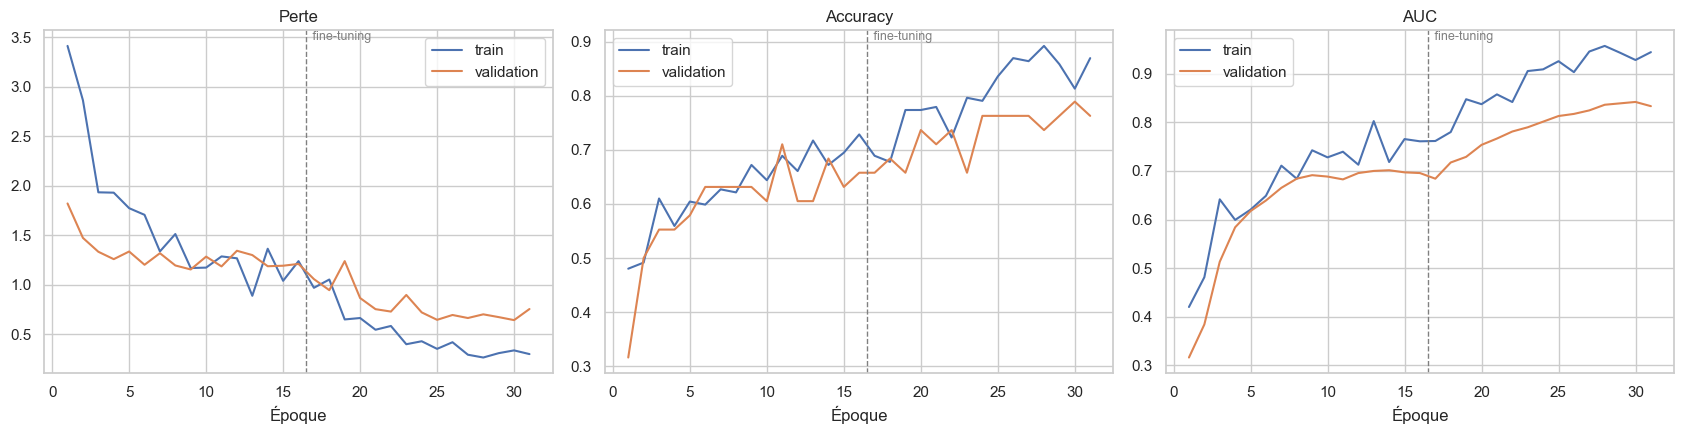

In [18]:
# Courbes d'apprentissage des deux phases mises bout à bout
historique = pd.concat([pd.DataFrame(hist1.history), pd.DataFrame(hist2.history)], ignore_index=True)
historique.index += 1
fin_phase1 = len(hist1.history["loss"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metrique, titre in zip(axes, ["loss", "accuracy", "auc"], ["Perte", "Accuracy", "AUC"]):
    ax.plot(historique[metrique], label="train")
    ax.plot(historique[f"val_{metrique}"], label="validation")
    ax.axvline(fin_phase1 + 0.5, color="grey", ls="--", lw=1)
    ax.text(fin_phase1 + 0.7, ax.get_ylim()[1], " fine-tuning", va="top", color="grey", fontsize=9)
    ax.set_title(titre); ax.set_xlabel("Époque"); ax.legend()
plt.tight_layout()
plt.show()

## 8. Évaluation sur le jeu de test

Le jeu de test n'a jamais été vu pendant l'entraînement ni pendant le réglage.

In [19]:
proba_test = modele.predict(ds_test, verbose=0).ravel()
pred_test = (proba_test >= CONFIG["seuil"]).astype(int)

print(classification_report(y_test, pred_test, target_names=CLASSES, digits=3))
print(f"AUC ROC : {roc_auc_score(y_test, proba_test):.3f}")

              precision    recall  f1-score   support

         non      0.889     0.533     0.667        15
         oui      0.759     0.957     0.846        23

    accuracy                          0.789        38
   macro avg      0.824     0.745     0.756        38
weighted avg      0.810     0.789     0.775        38

AUC ROC : 0.867


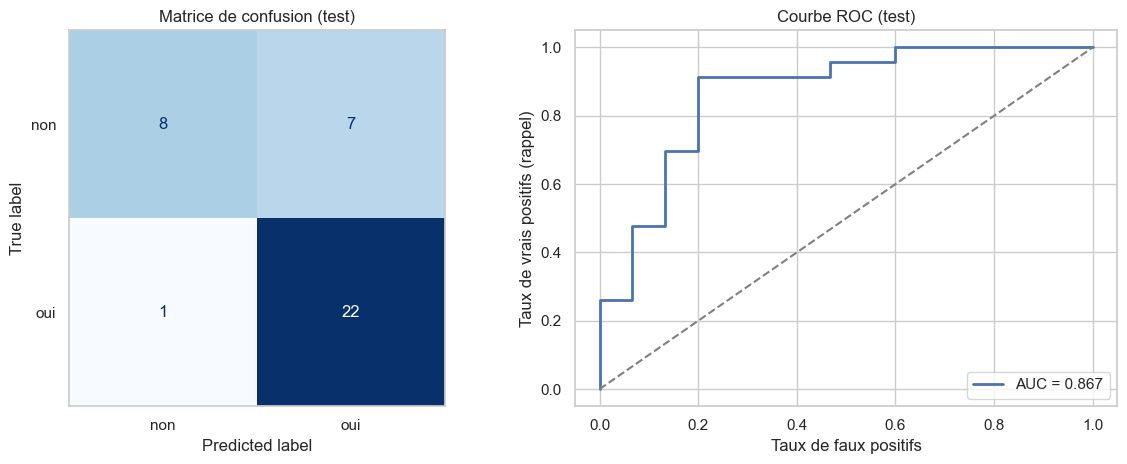

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=CLASSES).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matrice de confusion (test)")
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, proba_test):.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("Taux de faux positifs"); axes[1].set_ylabel("Taux de vrais positifs (rappel)")
axes[1].set_title("Courbe ROC (test)"); axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

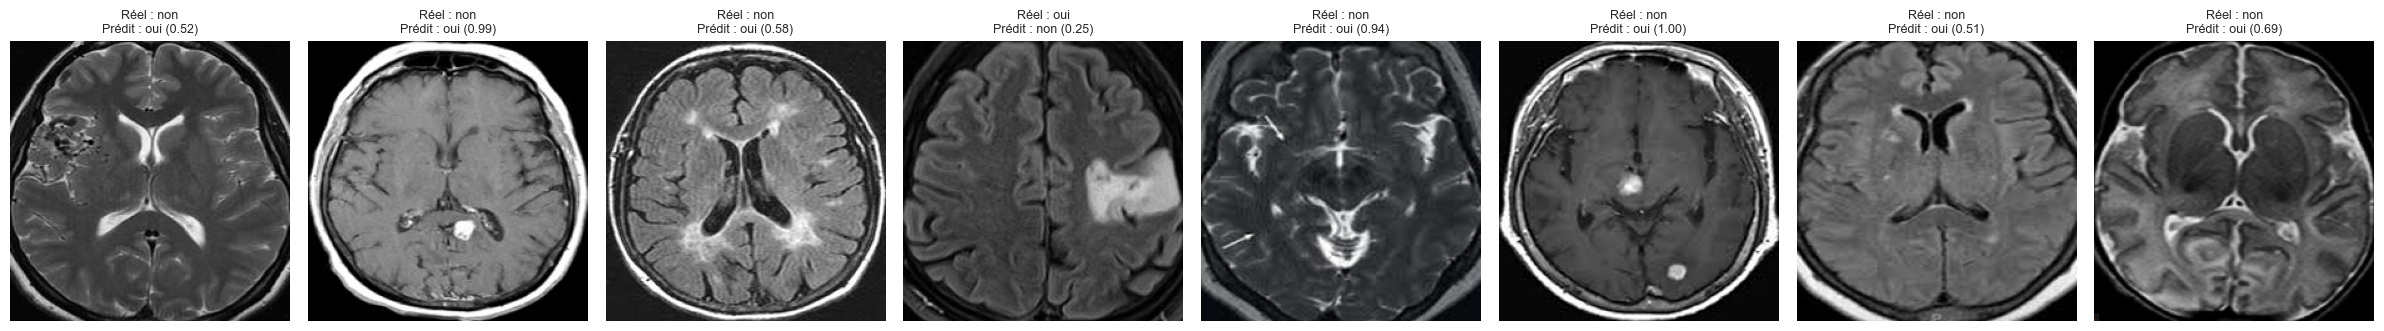

In [21]:
# Analyse des erreurs : quelles images le modèle rate-t-il ?
erreurs = np.where(pred_test != y_test)[0]
if len(erreurs) == 0:
    print("Aucune erreur sur le jeu de test.")
else:
    fig, axes = plt.subplots(1, len(erreurs), figsize=(3 * len(erreurs), 3.4), squeeze=False)
    for ax, i in zip(axes[0], erreurs):
        ax.imshow(X_test[i].astype("uint8"))
        ax.set_title(f"Réel : {CLASSES[int(y_test[i])]}\nPrédit : {CLASSES[pred_test[i]]} ({proba_test[i]:.2f})",
                     fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 9. Export ONNX pour le déploiement sur OpenShift AI

Le modèle sera servi sur **OpenShift AI** avec le runtime **OpenVINO Model Server** (KServe), qui lit l'ONNX nativement. Quelques choix pour que l'artefact soit propre à servir :

- **Graphe d'inférence dédié** : on reconstruit le modèle **sans les couches d'augmentation**, qui n'ont rien à faire en production, en réutilisant les couches entraînées. Les poids sont partagés, il n'y a pas de copie.
- **Prétraitement VGG16 embarqué** : `preprocess_input` (RGB→BGR + soustraction de la moyenne ImageNet) fait partie du graphe. Le client envoie simplement des pixels RGB 0–255.
- **Contrat d'API explicite** : entrée `irm` en `float32 [batch, 224, 224, 3]`, sortie `proba_tumeur` en `float32 [batch, 1]`.
- **Arborescence versionnée** `deploiement/vgg16-tumeur/1/model.onnx`, attendue par OpenVINO Model Server.

> Le recadrage du cerveau (OpenCV) reste **côté client** : il doit être appliqué avant l'appel au modèle, comme dans `predire_irm` plus bas.

In [22]:
# Modèle d'inférence : mêmes couches entraînées, sans augmentation
entree_inf = keras.Input(shape=CONFIG["taille_img"] + (3,), name="irm")
x = modele.get_layer("pretraitement_vgg")(entree_inf)
x = base_vgg(x, training=False)
x = modele.get_layer("gap")(x)
x = modele.get_layer("dropout")(x)           # inactive en inférence
sortie_inf = modele.get_layer("proba_tumeur")(x)
modele_inference = keras.Model(entree_inf, sortie_inf, name="vgg16_tumeur_inference")

# Sauvegarde Keras (pour réentraîner ou comparer plus tard)
Path("modeles").mkdir(exist_ok=True)
modele_inference.save(Path("modeles") / "vgg16_tumeur_cerebrale.keras")

In [23]:
import onnx
import onnxruntime as ort

dossier_onnx = Path("deploiement") / "vgg16-tumeur" / "1"
dossier_onnx.mkdir(parents=True, exist_ok=True)
chemin_onnx = dossier_onnx / "model.onnx"

signature = [tf.TensorSpec([None, *CONFIG["taille_img"], 3], tf.float32, name="irm")]
modele_inference.export(str(chemin_onnx), format="onnx", input_signature=signature)

# Nettoyage du graphe : sortie nommée "proba_tumeur" (au lieu de "Identity:0") et dimension batch lisible
graphe = onnx.load(chemin_onnx)
ancien_nom = graphe.graph.output[0].name
for noeud in graphe.graph.node:
    noeud.output[:] = ["proba_tumeur" if o == ancien_nom else o for o in noeud.output]
graphe.graph.output[0].name = "proba_tumeur"
graphe.graph.input[0].type.tensor_type.shape.dim[0].dim_param = "batch"
graphe.graph.output[0].type.tensor_type.shape.dim[0].dim_param = "batch"
onnx.checker.check_model(graphe)
onnx.save(graphe, chemin_onnx)

print(f"Modèle ONNX : {chemin_onnx} ({chemin_onnx.stat().st_size / 1e6:.1f} Mo, opset {graphe.opset_import[0].version})")

Saved artifact at 'deploiement\vgg16-tumeur\1\model.onnx'.


Modèle ONNX : deploiement\vgg16-tumeur\1\model.onnx (58.9 Mo, opset 15)

In [24]:
# Vérification : l'ONNX doit donner les mêmes probabilités que Keras sur tout le jeu de test
session = ort.InferenceSession(str(chemin_onnx), providers=["CPUExecutionProvider"])
print("Entrée :", [(i.name, i.shape, i.type) for i in session.get_inputs()])
print("Sortie :", [(o.name, o.shape, o.type) for o in session.get_outputs()])

proba_keras = modele_inference.predict(X_test, verbose=0).ravel()
proba_onnx = session.run(["proba_tumeur"], {"irm": X_test})[0].ravel()

print(f"Écart max Keras / ONNX : {np.abs(proba_keras - proba_onnx).max():.2e}")
print("Prédictions identiques :", np.array_equal(proba_keras >= CONFIG["seuil"], proba_onnx >= CONFIG["seuil"]))

Entrée : [('irm', ['batch', 224, 224, 3], 'tensor(float)')]
Sortie : [('proba_tumeur', ['batch', 1], 'tensor(float)')]


Écart max Keras / ONNX : 6.56e-07
Prédictions identiques : True


In [25]:
def preparer_irm(chemin_image):
    """Prétraitement côté client : lecture RGB, recadrage du cerveau, redimensionnement 224x224."""
    img = cv2.resize(recadrer_cerveau(lire_rgb(chemin_image)), CONFIG["taille_img"],
                     interpolation=cv2.INTER_CUBIC)
    return img.astype("float32")[None, ...]

def predire_irm(chemin_image, session=session):
    """Chaîne complète d'inférence avec le modèle ONNX (celui qui sera déployé)."""
    proba = float(session.run(["proba_tumeur"], {"irm": preparer_irm(chemin_image)})[0][0, 0])
    verdict = "tumeur détectée" if proba >= CONFIG["seuil"] else "pas de tumeur"
    return verdict, proba

# Démonstration sur quelques images du jeu de test
for _, ligne in test.sample(4, random_state=1).iterrows():
    verdict, proba = predire_irm(ligne["chemin"])
    print(f"{Path(ligne['chemin']).name:<15} réel = {ligne['classe']:<4} -> {verdict} (p = {proba:.2f})")

Y39.jpg         réel = oui  -> tumeur détectée (p = 1.00)


no 9.png        réel = non  -> pas de tumeur (p = 0.28)
N3.jpg          réel = non  -> pas de tumeur (p = 0.13)


Y170.JPG        réel = oui  -> tumeur détectée (p = 1.00)


### Déploiement

Les fichiers prêts à l'emploi se trouvent dans `deploiement/` :

| Fichier | Rôle |
|---|---|
| `vgg16-tumeur/1/model.onnx` | modèle à téléverser dans le stockage (bucket S3 ou PVC) |
| `inference-service.yaml` | `InferenceService` KServe pour le runtime OpenVINO |
| `client_kserve.py` | client de test : recadrage + appel REST au protocole KServe v2 |

Étapes :
1. Téléverser le dossier `vgg16-tumeur/` (avec son sous-dossier `1/`) dans le bucket de la data connection.
2. `oc apply -f deploiement/inference-service.yaml -n <namespace>`, ou passer par le dashboard OpenShift AI (*Deploy model* → format **onnx - 1** → runtime **OpenVINO Model Server**, chemin `vgg16-tumeur`).
3. `python deploiement/client_kserve.py --url https://<route> --image <irm.jpg>`

## Conclusion

**Résultats sur le jeu de test** (38 images jamais vues pendant l'entraînement) :

| Métrique | Valeur |
|---|---|
| Accuracy | **0.79** |
| AUC ROC | **0.87** |
| Rappel « oui » (tumeurs détectées) | **0.96** (22/23) |
| Rappel « non » | 0.53 |
| Précision « oui » | 0.76 |

**Ce que je retiens :**

- **Le fine-tuning fait la différence.** Avec VGG16 gelé, l'AUC de validation plafonne autour de 0.70. Dégeler le bloc 5 la fait monter à 0.84.
- **Le modèle est prudent.** Il rate très peu de tumeurs (1 sur 23), mais génère des faux positifs : environ la moitié des IRM saines sont signalées. Pour un outil de pré-tri, c'est le bon sens d'erreur, mais il reste du travail sur la spécificité.
- **Le taux d'apprentissage compte beaucoup.** À 1e-4, la tête n'apprenait quasiment rien en 30 époques. À 1e-3, elle converge. Une régression logistique sur les features VGG16 non augmentées atteint déjà une AUC de 0.91 en validation, ce qui laisse penser que l'augmentation actuelle est trop forte pour un jeu aussi petit.
- **Les chiffres restent fragiles.** Avec 38 images de test, une seule erreur fait varier l'accuracy de 2,6 points.

**Pistes d'amélioration :**

1. Alléger l'augmentation pendant la phase 1 et la garder pour le fine-tuning.
2. Ajuster le seuil de décision sur la validation, au lieu de 0.5, selon le compromis rappel / spécificité voulu.
3. Faire une validation croisée stratifiée (5 folds) pour obtenir des métriques plus fiables.
4. Enrichir les données avec un dataset IRM plus large (par exemple *Brain Tumor MRI Dataset*, ~7 000 images).

**Déploiement :** le modèle est exporté en ONNX (`deploiement/vgg16-tumeur/1/model.onnx`, 59 Mo). Il a été vérifié identique à Keras (écart < 1e-6) et il est prêt pour OpenVINO Model Server sur OpenShift AI.
